In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

rng = np.random.default_rng(42)

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True

In [2]:

# Training population
n_train = 5000
X_train = rng.normal(0, 1, size=(n_train, 2))

# Fraud probability depends on both features
logits = 3 * X_train[:, 0] + 1.5 * X_train[:, 1]
probabilities = 1 / (1 + np.exp(-logits))

y_train = rng.binomial(1, probabilities)

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

print("Model coefficients:", model.coef_)
print("Training accuracy:", round(model.score(X_train, y_train), 3))


Model coefficients: [[2.89192951 1.47795057]]
Training accuracy: 0.848


In [3]:

n_days = 100
samples_per_day = 500

daily_results = []

for day in range(1, n_days + 1):

    # Same feature distribution every day
    X_day = rng.normal(0, 1, size=(samples_per_day, 2))

    # Gradually change the underlying relationship
    if day <= 40:
        beta = 3.0
    elif day <= 70:
        beta = 3.0 - 6.0 * (day - 40) / 30
    else:
        beta = -3.0

    # Ground-truth fraud probability
    logits_day = beta * X_day[:, 0] + 1.5 * X_day[:, 1]
    true_prob = 1 / (1 + np.exp(-logits_day))
    y_day = rng.binomial(1, true_prob)

    # Predictions from our frozen model
    predicted_prob = model.predict_proba(X_day)[:, 1]
    predicted_label = (predicted_prob >= 0.5).astype(int)

    # Evaluate performance
    accuracy = accuracy_score(y_day, predicted_label)
    auc = roc_auc_score(y_day, predicted_prob)

    # Detect distribution changes in feature X1
    ks_stat, ks_p = ks_2samp(X_train[:, 0], X_day[:, 0])

    daily_results.append({
        "day": day,
        "beta": beta,
        "accuracy": accuracy,
        "roc_auc": auc,
        "mean_prediction": predicted_prob.mean(),
        "ks_statistic": ks_stat,
        "ks_pvalue": ks_p
    })

df = pd.DataFrame(daily_results)

print(df.head())
print("\nSimulation complete!")


   day  beta  accuracy   roc_auc  mean_prediction  ks_statistic  ks_pvalue
0    1   3.0     0.850  0.937984         0.489265        0.0560   0.112043
1    2   3.0     0.832  0.928879         0.553127        0.0808   0.005037
2    3   3.0     0.838  0.925506         0.522758        0.0662   0.035844
3    4   3.0     0.862  0.949597         0.552371        0.0680   0.028741
4    5   3.0     0.860  0.947784         0.510125        0.0430   0.361680

Simulation complete!


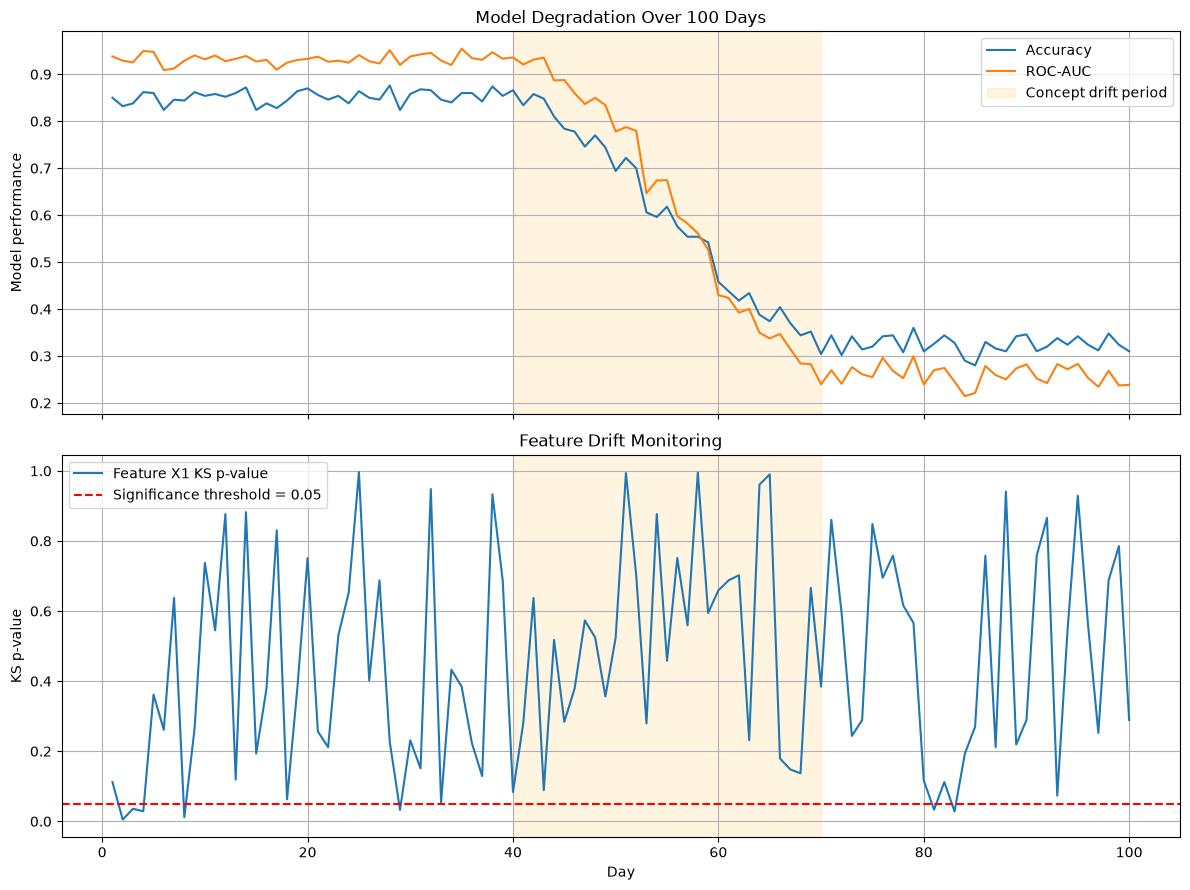

In [4]:

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# Performance
axes[0].plot(df["day"], df["accuracy"], label="Accuracy")
axes[0].plot(df["day"], df["roc_auc"], label="ROC-AUC")

axes[0].axvspan(40, 70, alpha=0.12, color="orange",
                label="Concept drift period")

axes[0].set_ylabel("Model performance")
axes[0].set_title("Model Degradation Over 100 Days")
axes[0].legend()

# Input feature drift
axes[1].plot(df["day"], df["ks_pvalue"],
             label="Feature X1 KS p-value")

axes[1].axhline(0.05, color="red", linestyle="--",
                label="Significance threshold = 0.05")

axes[1].axvspan(40, 70, alpha=0.12, color="orange")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("KS p-value")
axes[1].set_title("Feature Drift Monitoring")
axes[1].legend()

plt.tight_layout()
plt.show()


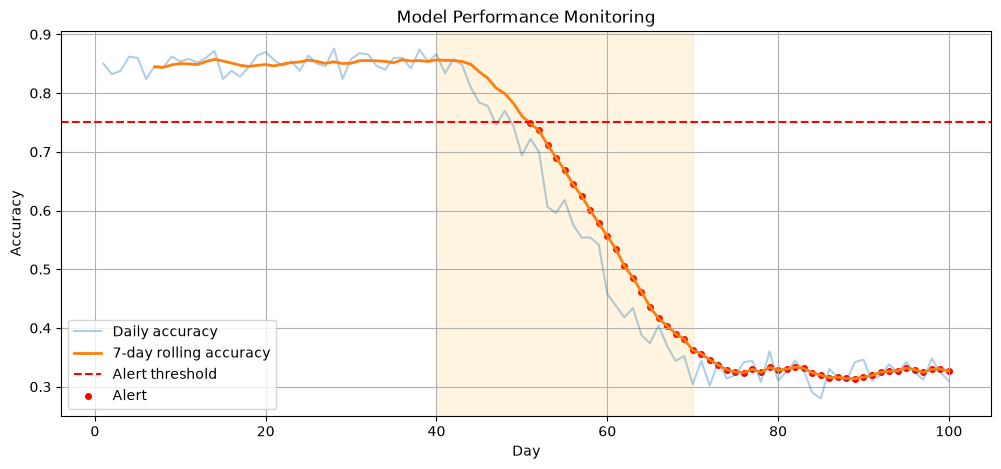

First performance alert: Day 51


In [5]:

df["rolling_accuracy"] = (
    df["accuracy"]
    .rolling(window=7, min_periods=7)
    .mean()
)

df["performance_alert"] = df["rolling_accuracy"] < 0.75

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df["day"], df["accuracy"],
        alpha=0.35, label="Daily accuracy")

ax.plot(df["day"], df["rolling_accuracy"],
        linewidth=2, label="7-day rolling accuracy")

ax.axhline(0.75, color="red",
           linestyle="--", label="Alert threshold")

alerts = df[df["performance_alert"]]

ax.scatter(alerts["day"], alerts["rolling_accuracy"],
           color="red", s=16, label="Alert")

ax.axvspan(40, 70, alpha=0.12, color="orange")

ax.set_title("Model Performance Monitoring")
ax.set_xlabel("Day")
ax.set_ylabel("Accuracy")
ax.legend()

plt.show()

if len(alerts):
    print("First performance alert: Day", int(alerts.iloc[0]["day"]))
else:
    print("No performance alerts triggered")


In [6]:

label_delay = 14

# Performance for day d becomes observable on day d+14
df["observed_day"] = df["day"] + label_delay

available_metrics = df[
    df["observed_day"] <= n_days
].copy()

available_metrics["alert_with_delay"] = (
    available_metrics["rolling_accuracy"] < 0.75
)

first_alert = available_metrics.loc[
    available_metrics["alert_with_delay"], "observed_day"
]

print("First alert with immediate labels:",
      int(alerts.iloc[0]["day"]) if len(alerts) else None)

print("First alert with 14-day label delay:",
      int(first_alert.iloc[0]) if len(first_alert) else None)


First alert with immediate labels: 51
First alert with 14-day label delay: 65
